In [2]:
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import pandas as pd
import os
import ast
from configparser import ConfigParser

In [4]:
DATAPATH = '../../data/output'
CONFIGPATH = '../configurations/app-remote.ini'
RESULTS = 'average_10_experiments_20211202-000820.csv'
parser = ConfigParser()
parser.read(CONFIGPATH)

# Configuration
episodes = int(parser.get("BUS", "EPISODES"))
timelimit = parser.getfloat("BUS", "TIMELIMIT") # multiplier, not the real timelimit
actions = parser.get("BUS", "ACTION_SPACE").split(',')
action_dim = len(actions)
action_resolution = parser.getint("BUS", "ACTION_SPACE_RESOLUTION")
eps = parser.getfloat("BUS", "EPS")
eps_decay = parser.getfloat("BUS", "EPS_DECAY")
eps_min = parser.getfloat("BUS", "EPS_MIN")
buffersize = int(parser.get("BUS", "BUFFERSIZE"))
min_experience = int(parser.get("BUS", "MIN_EXPERIENCE"))
target_update_threshold = int(parser.get("BUS", "TARGET_UPDATE_THRESHOLD"))
tau = parser.getfloat("BUS", "TAU")
gamma = parser.getfloat("BUS", "GAMMA")
penalty = int(parser.get("BUS", "PENALTY"))
reward = parser.getint("BUS", "REWARD")
q_net_layers = ast.literal_eval(parser.get("BUS", "DQN_LAYERS"))
batchsize = int(parser.get("BUS", "BATCHSIZE"))
lr_decay = parser.getboolean("BUS", "LR_DECAY")
lr_decay_steps = parser.getint("BUS", "LR_DECAY_STEPS")
velocity = float(parser.get("BUS", "VELOCITY"))

config = {'episodes': episodes, 
          'actions': actions,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'penalty': penalty,
          'learning rate decay': lr_decay,
          'batchsize': batchsize
         }

# Experiment with different agent configurations

In [9]:
RESULTS = 'search_doubleQ_experiments_20211207-195135.csv'
COLS = ['episode', 'return', 'service_level', 'lr', 'reached_destination', 'distance', 'duration']

config = {'episodes': episodes, 
          'actions': actions,
          'timelimit multiplier': timelimit,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# TODO: put in variable instead of if blocks for each possible experiment
experiments = list(set(results) - set(COLS))
for e in experiments:
    config.pop(e) # remove this from configuration legend

n_experiments = len(experiments)
if n_experiments > 2:
    raise NotImplementedError('more than two simultaneous experiments are currently not supported')
elif n_experiments == 2:
    e1 = results[experiments[0]]
    e2 = results[experiments[1]]
    n_e1 = e1.nunique()
    n_e2 = e2.nunique()
    fig, ax = plt.subplots(n_e1, n_e2, figsize=(8*n_e1,5*n_e2))
    ii = 0
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()
        
        if i >= n_e1:
            ii = i // n_e1
            i -= n_e1

        # annotations
        ax[ii][i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[ii][i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[ii][i].twinx()
        ax2 = ax[ii][i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[ii][i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Reward: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[ii][i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]

elif n_experiments == 1:
    n = results[experiments[0]].nunique()
    fig, ax = plt.subplots(n, figsize=(10,5*n))
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Reward: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

KeyError: 'doubleQ'

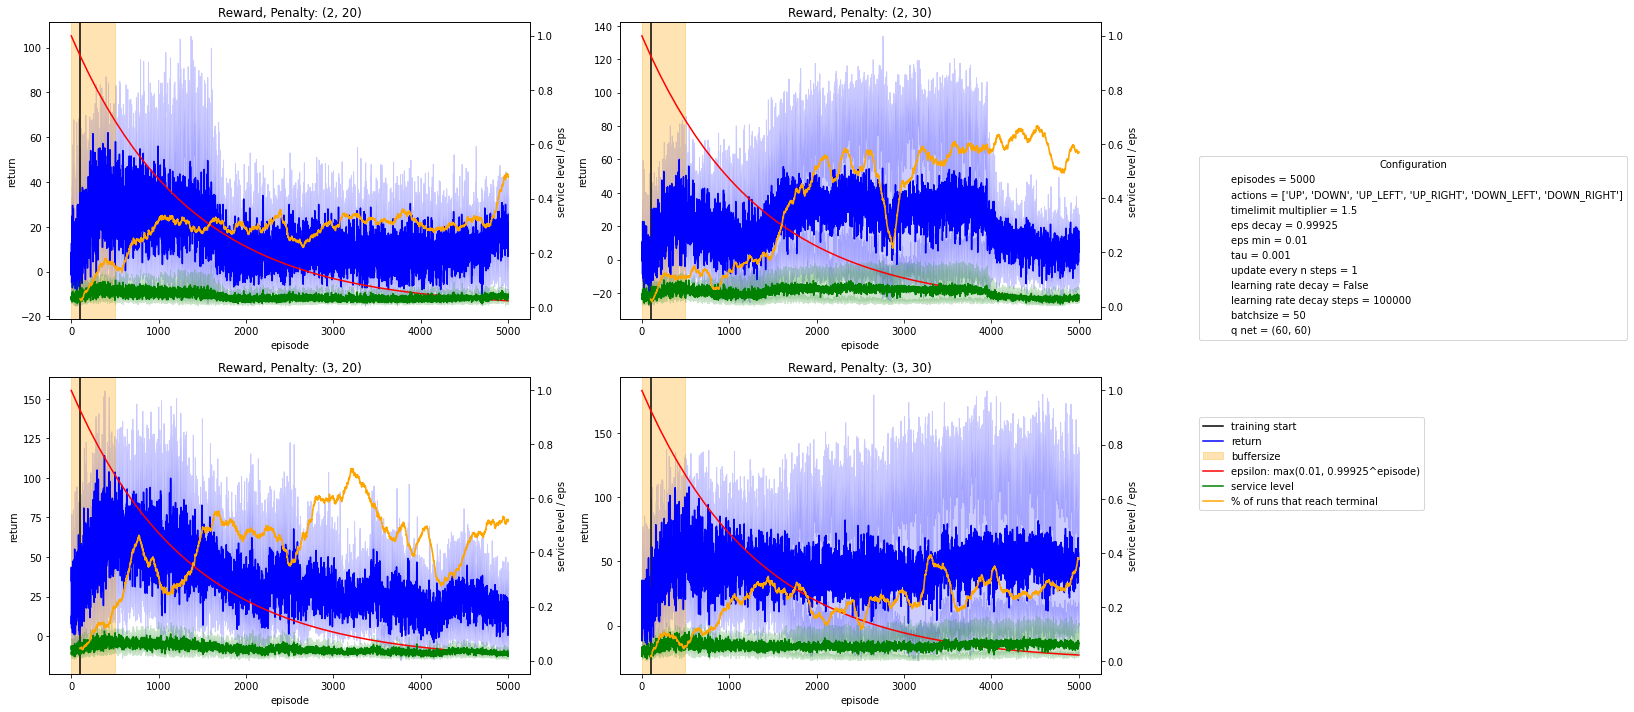

In [8]:
RESULTS = 'search_reward_experiments_20211211-172120.csv'
COLS = ['episode', 'return', 'service_level', 'lr', 'reached_destination', 'distance', 'duration']

config = {'episodes': episodes, 
          'actions': actions,
          'timelimit multiplier': timelimit,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# TODO: put in variable instead of if blocks for each possible experiment
experiments = list(set(results) - set(COLS))

if 'buffersize' in list(results):
    fig, ax = plt.subplots(results['buffersize'].nunique(), figsize=(10,15))
    for i, (name, group) in enumerate(results.groupby('buffersize')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Buffersize: {name}')

if 'action_space' in list(results):
    experiments = results['action_space'].nunique()
    config.pop('actions') # remove this from configuration legend
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('action_space')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Action space: {name}')
        
if 'lr_decay' in list(results):
    experiments = results['lr_decay'].nunique()
    config.pop('learning rate decay') # remove this from configuration legend
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('lr_decay')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()
        
        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[i], legend=False)
#         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
#         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Decaying Learning Rate: {name}')
        
if 'reward' in list(results):
    experiments = results['reward'].nunique()
    config.pop('reward') # remove this from configuration legend
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('reward')):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        # hide this axis
        ax_.set_axis_off()
        
        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[i], legend=False)
#         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
#         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)
    
        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Reward: {name}')

handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

<AxesSubplot:xlabel='episode', ylabel='reached_destination'>

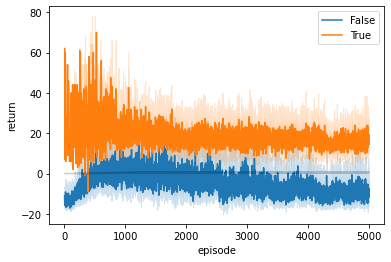

In [116]:
fig, ax = plt.subplots()
sns.lineplot(ax=ax, data=results, x='episode', y='return', hue='reached_destination')
reached = results.groupby('episode')['reached_destination'].mean().rolling(100).mean().reset_index()
ax2 = ax.twinx()
sns.lineplot(ax=ax2, data=reached, x='episode', y='reached_destination', color='black', alpha=.2)

# Single (averaged) agent evaluation

In [83]:
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(20).mean()
results['service_level_MA'] = results['service_level'].rolling(20).mean()

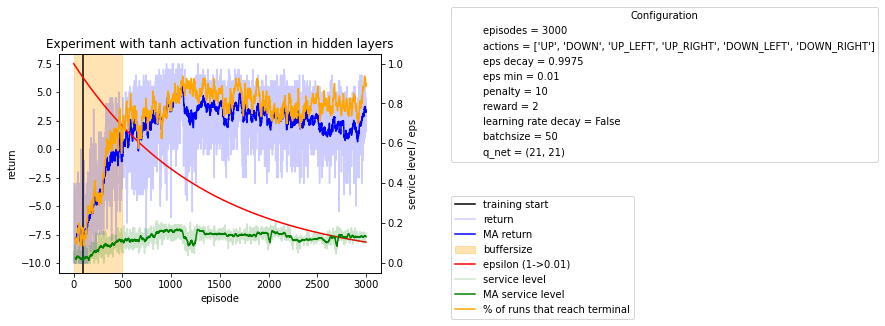

In [84]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
plt.axvline(min_experience, color='black', label='training start')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
sns.lineplot(x=x_, y=np.maximum(0.99925**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
ax_.set_axis_off() # hide this axis

sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

plt.title('Experiment with Penalty = 15, soft update with tau=0.001 at every step')
fig.patch.set_facecolor('white')
ax2.set_ylabel('service level / eps')
fig.legend(bbox_to_anchor=(1.04,0.5), loc="center left")
fig.show()

## find best of runs

In [3]:
runs = [
    '3000_episodes_returns_20211211-004244.csv',
    '3000_episodes_returns_20211211-004708.csv',
    '3000_episodes_returns_20211211-005104.csv',
    '3000_episodes_returns_20211211-005223.csv'
]

In [7]:
for r in runs:
    run_results = pd.read_csv(os.path.join(DATAPATH, r))
    print(f'Run {r}: \n\tMean service level: {run_results["service_level"].mean()} \n\tMean of reaching destination: {run_results["reached_destination"].mean()}\n')

Run 3000_episodes_returns_20211211-004244.csv: 
	Mean service level: 0.1074613183113183 
	Mean of reaching destination: 0.759

Run 3000_episodes_returns_20211211-004708.csv: 
	Mean service level: 0.10074243904243904 
	Mean of reaching destination: 0.646

Run 3000_episodes_returns_20211211-005104.csv: 
	Mean service level: 0.15199797702297702 
	Mean of reaching destination: 0.8323333333333334

Run 3000_episodes_returns_20211211-005223.csv: 
	Mean service level: 0.13393815813815813 
	Mean of reaching destination: 0.6946666666666667



# Benchmark best run

In [2]:
BENCHMARK = '100_episodes_benchmark_20211212-164813.csv'
ROLLING = 10

<AxesSubplot:xlabel='episode', ylabel='service_level_MA'>

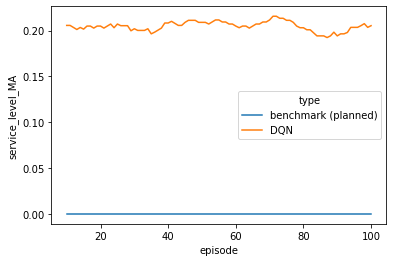

In [5]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK))
# noinspection JupyterPackage
benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level'].rolling(ROLLING).mean()

sns.lineplot(data=benchmark_results, x='episode', y='service_level_MA', hue='type')

In [6]:
benchmark_results.groupby('type').describe()['service_level']

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
DQN,100.0,0.204818,0.016349,0.166667,0.2,0.2,0.222222,0.222222
benchmark (planned),100.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
